# Introduction to Data Science 2026

# Week 2

## Exercise 1 | Titanic: data preprocessing and imputation
<span style="font-weight: bold"> *Note: You can find tutorials for NumPy and Pandas under 'Useful tutorials' in the course material.*</span>

Download the [Titanic dataset](https://www.kaggle.com/c/titanic) [train.csv] from Kaggle or <span style="font-weight: 500">directly from the course material</span>, and complete the following exercises. If you choose to download the dataset from Kaggle, you will need to create a Kaggle account unless you already have one, but it is quite straightforward.

The dataset consists of personal information of all the passengers on board the RMS Titanic, along with information about whether they survived the iceberg collision or not.

1. Your first task is to read the data file and print the shape of the data.

    <span style="font-weight: 500"> *Hint 1: You can read them into a Pandas dataframe if you wish.*</span>
    
    <span style="font-weight: 500"> *Hint 2: The shape of the data should be (891, 12).*</span>

In [35]:
import pandas as pd

df = pd.read_csv('train.csv')

df.shape

(891, 12)

2. Let's look at the data and get started with some preprocessing. Some of the columns, e.g <span style="font-weight: 500"> *Name*</span>, simply identify a person and are not useful for prediction tasks. Try to identify these columns, and remove them.

    <span style="font-weight: 500"> *Hint: The shape of the data should now be (891, 9).*</span>

In [36]:
df.drop(columns= ['Name', 'PassengerId', 'Ticket'], inplace=True)

df.shape

(891, 9)

3. The column <span style="font-weight: 500">*Cabin*</span> contains a letter and a number. A smart catch at this point would be to notice that the letter stands for the deck level on the ship. Keeping just the deck information would be more informative when developing, e.g. a classifier that predicts whether a passenger survived. The next step in our preprocessing will be to add a new column to the dataset, which consists simply of the deck letter. You can then remove the original <span style="font-weight: 500">*Cabin*</span>-column.

<span style="font-weight: 500">*Hint: The deck letters should be ['A' 'B' 'C' 'D' 'E' 'F' 'G' 'T'].*</span>

In [37]:
df['Deck'] = df['Cabin'].str[0]

df.drop(columns= ['Cabin'], inplace=True)

df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Deck
0,0,3,male,22.0,1,0,7.2500,S,NaN
1,1,1,female,38.0,1,0,71.2833,C,C
2,1,3,female,26.0,0,0,7.9250,S,NaN
3,1,1,female,35.0,1,0,53.1000,S,C
4,0,3,male,35.0,0,0,8.0500,S,NaN


4. You’ll notice that some of the columns, such as the previously added deck number, are [categorical](https://en.wikipedia.org/wiki/Categorical_variable). To preprocess the categorical variables so that they're ready for further computation, we need to avoid the current string format of the values. This means the next step for each categorical variable is to transform the string values to numeric ones, that correspond to a unique integer ID representative of each distinct category. This process is called label encoding and you can read more about it [here](https://pandas.pydata.org/docs/user_guide/categorical.html).

    <span style="font-weight: 500">*Hint: Pandas can do this for you.*</span>

In [38]:
df['Deck'].unique()

<StringArray>
[nan, 'C', 'E', 'G', 'D', 'A', 'B', 'F', 'T']
Length: 9, dtype: str

In [40]:
df['Embarked'].unique()

<StringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str

In [41]:
categorical_columns = ['Sex', 'Embarked', 'Deck']

for col in categorical_columns:
    df[col] = df[col].astype('category').cat.codes
# Sex: female = 0, male = 1
# Embarked: C = 0, Q = 1, S = 2; missing values = -1
# Deck: Cabin-deck letters become integer codes(0-7); missing values = -1
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Deck
0,0,3,1,22.0,1,0,7.2500,2,-1
1,1,1,0,38.0,1,0,71.2833,0,2
2,1,3,0,26.0,0,0,7.9250,2,-1
3,1,1,0,35.0,1,0,53.1000,2,2
4,0,3,1,35.0,0,0,8.0500,2,-1


5. Next, let's look into missing value **imputation**. Some of the rows in the data have missing values, e.g when the cabin number of a person is unknown. Most machine learning algorithms have trouble with missing values, and they need to be handled during preprocessing:

    a) For continuous variables, replace the missing values with the mean of the non-missing values of that column.

    b) For categorical variables, replace the missing values with the mode of the column.

    <span style="font-weight: 500">*Remember: Even though in the previous step we transformed categorical variables into their numeric representation, they are still categorical.*</span>

In [42]:
df.isnull().sum()

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      0
Deck          0
dtype: int64

In [43]:
# continuous
df['Age'] = df['Age'].fillna(df['Age'].mean())


# categorical
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

deck_mode = df.loc[df['Deck'] != -1, 'Deck'].mode()[0]
df['Deck'] = df['Deck'].replace(-1, deck_mode)

df.isnull().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
Deck        0
dtype: int64

6. At this point, all data is numeric. Write the data, with the modifications we made, to a  <span style="font-weight: 500"> .csv</span> file. Then, write another file, this time in <span style="font-weight: 500">JSON</span> format, with the following structure:

In [21]:
#[
#    {
#        "Deck": 0,
#        "Age": 20,
#        "Survived", 0
#        ...
#    },
#    {
#        ...
#    }
#]

In [44]:
df.to_csv('titanic_preprocessed.csv', index=False)

df.to_json(
    'titanic_preprocessed.json',
    orient='records',
    indent=4
)

Study the records and try to see if there is any evident pattern in terms of chances of survival.

**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**

## Exercise 2 | Titanic 2.0: exploratory data analysis

In this exercise, we’ll continue to study the Titanic dataset from the last exercise. Now that we have done some preprocessing, it’s time to look at the data with some exploratory data analysis.

1. First investigate each feature variable in turn. For each categorical variable, find out the mode, i.e., the most frequent value. For numerical variables, calculate the median value.

In [46]:
# continuous
numerical_cols = ['Age', 'SibSp', 'Parch', 'Fare']

for col in numerical_cols:
    print(f"{col} — median: {df[col].median()}")

# categorical
categorical_cols = ['Sex', 'Embarked', 'Deck', 'Pclass']

for col in categorical_cols:
    print(f"{col} — mode: {df[col].mode()[0]}")

Age — median: 29.69911764705882
SibSp — median: 0.0
Parch — median: 0.0
Fare — median: 14.4542
Sex — mode: 1
Embarked — mode: 2
Deck — mode: 2
Pclass — mode: 3


2. Next, combine the modes of the categorical variables, and the medians of the numerical variables, to construct an imaginary “average survivor”. This "average survivor" should represent the typical passenger of the class of passengers who survived. Also following the same principle, construct the “average non-survivor”.

    <span style="font-weight: 500">*Hint 1: What are the average/most frequent variable values for a non-survivor?*</span>
    
    <span style="font-weight: 500">*Hint 2: You can split the dataframe in two: one subset containing all the survivors and one consisting of all the non-survivor instances. Then, you can use the summary statistics of each of these dataframe to create a prototype "average survivor" and "average non-survivor", respectively.*</span>

In [47]:
# Split the dataset into the two outcome groups
survivors = df[df['Survived'] == 1]
non_survivors = df[df['Survived'] == 0]

# Create the prototype / "average" survivor
average_survivor = {}

for col in categorical_cols:
    average_survivor[col] = survivors[col].mode()[0]

for col in numerical_cols:
    average_survivor[col] = survivors[col].median()

# Create the prototype / "average" non-survivor
average_non_survivor = {}

for col in categorical_cols:
    average_non_survivor[col] = non_survivors[col].mode()[0]

for col in numerical_cols:
    average_non_survivor[col] = non_survivors[col].median()

# Display both profiles as a table
profiles = pd.DataFrame(
    [average_survivor, average_non_survivor],
    index=['Average survivor', 'Average non-survivor']
)

profiles

,Sex,Embarked,Deck,Pclass,Age,SibSp,Parch,Fare
Average survivor,0,2,2,1,29.699118,0.0,0.0,26.0
Average non-survivor,1,2,2,3,29.699118,0.0,0.0,10.5


3. Next, let's study the distributions of the variables in the two groups (survivor/non-survivor). How well do the average cases represent the respective groups? Can you find actual passengers that are very similar to the (average) representative of their own group? Can you find passengers that are very similar to the (average) representative of the other group?

    <span style="font-weight: 500">*Note: Feel free to choose EDA methods according to your preference: non-graphical/graphical, static/interactive - anything goes.*</span>

In [49]:
numerical_cols = ['Age', 'SibSp', 'Parch', 'Fare']

print(
    df.groupby('Survived')[numerical_cols]
      .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
      .round(2)
)

           Age                                  SibSp                     ...  \
         count   mean median    std   min   max count  mean median   std  ...   
Survived                                                                  ...   
0          549  30.42   29.7  12.46  1.00  74.0   549  0.55    0.0  1.29  ...   
1          342  28.55   29.7  13.77  0.42  80.0   342  0.47    0.0  0.71  ...   

          Parch                Fare                                    
         median   std min max count   mean median    std  min     max  
Survived                                                               
0           0.0  0.82   0   6   549  22.12   10.5  31.39  0.0  263.00  
1           0.0  0.77   0   5   342  48.40   26.0  66.60  0.0  512.33  

[2 rows x 24 columns]


In [54]:
categorical_cols = ['Pclass', 'Sex', 'Embarked', 'Deck']

for col in categorical_cols:
    print(f'\n- {col}')
    print(pd.crosstab(df[col], df['Survived'], normalize='columns'))


- Pclass
Survived         0         1
Pclass                      
1         0.145719  0.397661
2         0.176685  0.254386
3         0.677596  0.347953

- Sex
Survived         0         1
Sex                         
0         0.147541  0.681287
1         0.852459  0.318713

- Embarked
Survived         0         1
Embarked                    
-1        0.000000  0.005848
 0        0.136612  0.271930
 1        0.085610  0.087719
 2        0.777778  0.634503

- Deck
Survived         0         1
Deck                        
0         0.014572  0.020468
1         0.021858  0.102339
2         0.919854  0.704678
3         0.014572  0.073099
4         0.014572  0.070175
5         0.009107  0.023392
6         0.003643  0.005848
7         0.001821  0.000000


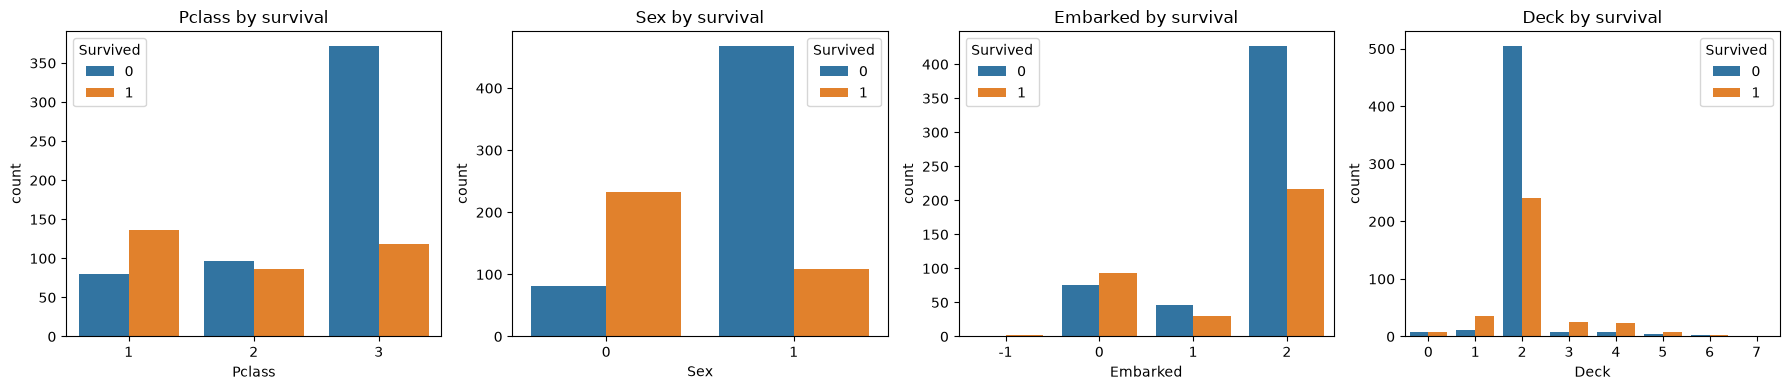

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

# Categorical distributions
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, col in zip(axes, categorical_cols):
    sns.countplot(data=df, x=col, hue='Survived', ax=ax)
    ax.set_title(f'{col} by survival')
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()

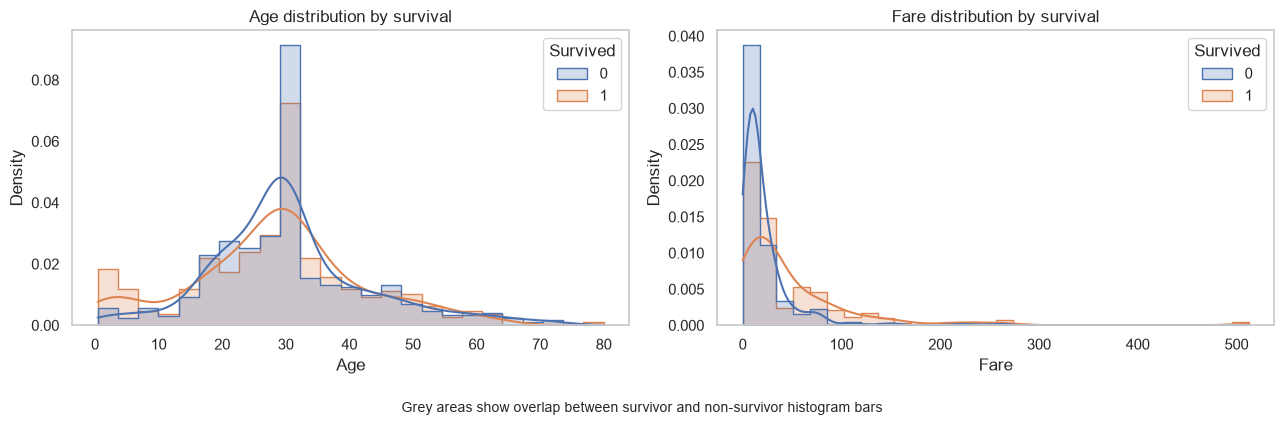

In [77]:
# Numeric distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    data=df, x='Age', hue='Survived',
    bins=25, kde=True, element='step',
    stat='density', common_norm=False, ax=axes[0]
)
axes[0].set_title('Age distribution by survival')
axes[0].grid(False)  # Remove grid

sns.histplot(
    data=df, x='Fare', hue='Survived',
    bins=30, kde=True, element='step',
    stat='density', common_norm=False, ax=axes[1]
)
axes[1].set_title('Fare distribution by survival')
axes[1].grid(False)  # Remove grid

plt.figtext(
    0.5,
    -0.05,
    'Grey areas show overlap between survivor and non-survivor histogram bars',
    ha='center',
    fontsize=10
)

plt.tight_layout()
plt.show()

4. Next, let's continue the analysis by looking into pairwise and multivariate relationships between the variables in the two groups. Try to visualize two variables at a time using, e.g., scatter plots and use a different color to encode the survival status.

    <span style="font-weight: 500">*Hint 1: You can also check out Seaborn's pairplot function, if you wish.*</span>

    <span style="font-weight: 500">*Hint 2: To better show many data points with the same value for a given variable, you can use either transparency or ‘jitter’.*</span>

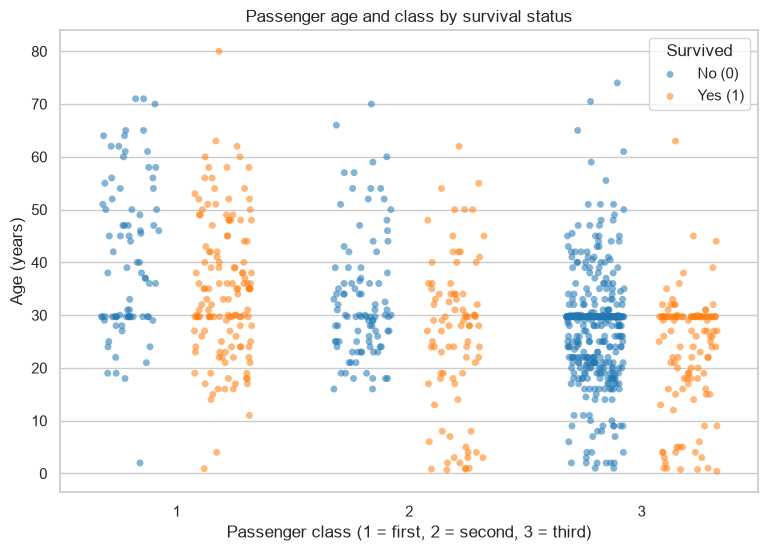

Text(0.5, 1.0, 'Age and fare by survival status')

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))

sns.stripplot(
    data=df,
    x='Pclass',
    y='Age',
    hue='Survived',
    dodge=True,
    jitter=0.25,
    alpha=0.55,
    palette={0: 'tab:blue', 1: 'tab:orange'}
)

plt.title('Passenger age and class by survival status')
plt.xlabel('Passenger class (1 = first, 2 = second, 3 = third)')
plt.ylabel('Age (years)')
plt.legend(title='Survived', labels=['No (0)', 'Yes (1)'])
plt.show()
axes[0].set_title('Age and fare by survival status')



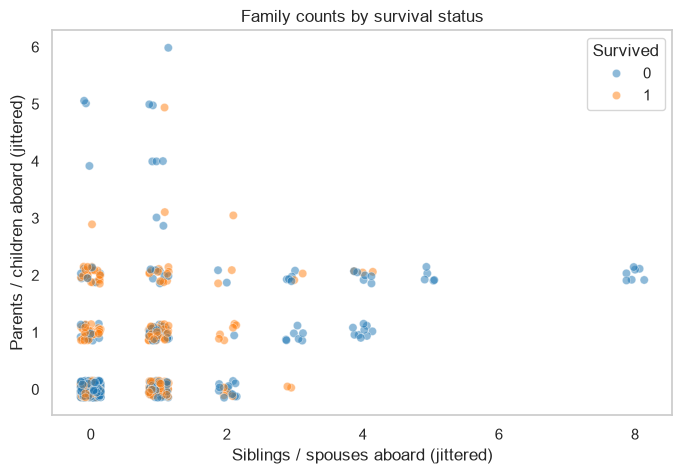

In [80]:
import numpy as np

plot_df = df.copy()

np.random.seed(42)
plot_df['SibSp_jitter'] = plot_df['SibSp'] + np.random.uniform(-0.15, 0.15, len(plot_df))
plot_df['Parch_jitter'] = plot_df['Parch'] + np.random.uniform(-0.15, 0.15, len(plot_df))

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=plot_df,
    x='SibSp_jitter',
    y='Parch_jitter',
    hue='Survived',
    palette={0: 'tab:blue', 1: 'tab:orange'},
    alpha=0.5
)

plt.title('Family counts by survival status')
plt.xlabel('Siblings / spouses aboard (jittered)')
plt.ylabel('Parents / children aboard (jittered)')

plt.grid(False)  # Remove grid lines
plt.show()

5. Finally, recall the preprocessing we did in the first exercise. What can you say about the effect of the choices that were made to use the mode and mean to impute missing values, instead of, for example, ignoring passengers with missing data?

Using mode and mean imputation keeps passengers with missing information in the dataset rather than dropping them. This preserves sample size and can make the analysis more stable.

For numerical variables such as Age, filling missing values with the mean places every missing observation at the same central value. It avoids losing rows and allows models and plots that require complete data to run. It can reduce the apparent variation in the variable because many observations receive exactly the same value. It may weaken relationships between age and survival: passengers with unknown ages are treated as “average age,” even though their true ages may systematically differ. For example, if missing ages are imputed as 29.7, a group of passengers whose actual ages were mostly children or older adults would be incorrectly represented as adults near 30. This could bias estimated survival patterns by age.

For categorical variables such as Embarked, filling missing values with the mode assigns all missing values to the most common category. It retains those passengers in the analysis. But it increases the count of the most common category, making it appear more prevalent than it truly was. It can hide a meaningful pattern if missing values came disproportionately from another port or passenger group. It tends to reduce category diversity and can bias comparisons across groups. For example, if the modal embarkation port is S, assigning every missing Embarked value to S may exaggerate the number of passengers from Southampton and affect any survival comparison by embarkation port.



**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**

## Exercise 3 | Working with text data 2.0

This exercise is related to the second exercise from last week. Find the saved <span style="font-weight: 500">pos.txt</span> and <span style="font-weight: 500">neg.txt</span> files, or, alternatively, you can find the week 1 example solutions on the MOOC platform after Tuesday.

1. Find the most common words in each file (positive and negative). Examine the results. Do they tend to be general terms relating to the nature of the data? How well do they indicate positive/negative sentiment?

In [85]:
from collections import Counter

def get_most_common_words(filename, top_n=20):
    with open(filename, "r", encoding="utf-8") as f:
        words = f.read().lower().split()

    return Counter(words).most_common(top_n)

positive_common = get_most_common_words("pos.txt")
negative_common = get_most_common_words("neg.txt")

print("Most common words in positive.txt:")
for word, count in positive_common:
    print(f"{word}: {count}")

print("\nMost common words in negative.txt:")
for word, count in negative_common:
    print(f"{word}: {count}")

Most common words in positive.txt:
great: 435906
work: 427780
use: 345233
good: 291448
fit: 273505
instal: 229408
product: 210084
look: 181401
just: 180420
like: 175725
easi: 162864
light: 147321
car: 147195
price: 144891
need: 136519
perfect: 124405
time: 123938
replac: 122261
qualiti: 119732
nice: 119314

Most common words in negative.txt:
work: 39998
use: 37244
fit: 31293
product: 24394
just: 23580
light: 22907
like: 20685
time: 19665
look: 18824
instal: 18709
did: 18446
good: 17295
dont: 17136
buy: 16885
car: 16694
return: 15227
tri: 14957
doe: 14201
replac: 13509
didnt: 13045


Most frequent words are largely general product-review terms—for example, `work`, `fit`, `product`, `light`, `car`, and `instal`—so they describe the data’s topic more than its sentiment.

Some words do indicate sentiment: positive reviews contain `great`, `good`, `perfect`, and `nice`, while negative reviews include `dont`, `didnt`, and `return`. However, single words are limited because sentiment often depends on context: “works great” is positive, but “doesn’t work” is negative. Bigrams or phrases would identify sentiment more accurately.

2. Compute a [TF/IDF](https://en.wikipedia.org/wiki/Tf–idf) vector for each of the two text files, and make them into a <span style="font-weight: 500">2 x m</span> matrix, where <span style="font-weight: 500">m</span> is the number of unique words in the data. The problem with using the most common words in a review to analyze its contents is that words that are common overall will be common in all reviews (both positive and negative). This means that they probably are not good indicators about the sentiment of a specific review. TF/IDF stands for Term Frequency / Inverse Document Frequency (here the reviews are the documents), and is designed to help by taking into consideration not just the number of times a term occurs (term frequency), but also how many times a word exists in other reviews as well (inverse document frequency). You can use any variant of the formula, as well as off-the-shelf implementations. <span style="font-weight: 500">*Hint: You can use [sklearn](http://scikit-learn.org/).*</span>

In [28]:
# Use this cell for your code

3. List the words with the highest TF/IDF score in each class (positive | negative), and compare them to the most common words. What do you notice? Did TF/IDF work as expected?

In [29]:
# Use this cell for your code

4. Plot the words in each class with their corresponding TF/IDF scores. Note that there will be a lot of words, so you’ll have to think carefully to make your chart clear! If you can’t plot them all, plot a subset – think about how you should choose this subset.

    <span style="font-weight: 500">*Hint: you can use word clouds. But feel free to challenge yourselves to think of any other meaningful way to visualize this information!*</span>

In [30]:
# Use this cell for your code

**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**

## Exercise 4 | Junk charts

There’s a thriving community of chart enthusiasts who keep looking for statistical graphics that they find inappropriate, and which they call “junk charts”, and who often also propose ways to improve them.

1. Find at least three statistical visualizations you think are not very good and identify their problems. Copying examples from various junk chart websites is not accepted – you should find your own junk charts, out in the wild. You should be able to find good (or rather, bad) examples quite easily since a significant fraction of charts can have at least *some* issues. The examples you choose should also have different problems, e.g., try to avoid collecting three bar charts, all with problematic axes. Instead, try to find as interesting and diverse examples as you can.

2. Try to produce improved versions of the charts you selected. The data is of course often not available, but perhaps you can try to extract it, at least approximately, from the chart. Or perhaps you can simulate data that looks similar enough to make the point.



**Submit a PDF with all the charts (the ones you found and the ones you produced).**